# Fewer, better tetrahedra: `adapt_volume`

`octree_mesh(output="tet")` fills a skin with valid, conforming tetrahedra by isosurface stuffing on a graded octree. It is robust, but it puts more tetrahedra in than a mesher working towards a size field would, and the graded skin leaves some poorly shaped ones. `adapt_volume` remeshes such a mesh towards an isotropic size field: it **collapses** short edges, **splits** long ones, **swaps** (2-3, 3-2, edge and multi-face removal) and **smooths**, under guards that keep every tetrahedron positive (exact `orient3d`), the least quality above a floor, the boundary within `hausd` of the input's, and the corners, ridges, materials and regions in place.

This notebook compares `octree_mesh`, `octree_mesh` followed by `adapt_volume`, and MMG's `mmg3d` at the same parameters when it is present (the optional `meshioplusplus-mmg` add-on, or the `mmg3d` program on `PATH`, run on a Medit file so nothing links it). See `doc/adapt_volume.md`.

In [1]:
import os

# Quiet the per-sweep notes of the relocation's inversion guard.
os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
import subprocess
import sys
import tempfile
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')

# Renders the documentation embeds are written here as well as shown.
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def show(img, title=None, figsize=(6, 4.5), save=None):
    """Embed a rendered RGB screenshot; with `save`, also write doc/public/images/<save>.png."""
    if save:
        try:
            os.makedirs(DOC_IMAGES, exist_ok=True)
            plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
        except Exception as exc:  # pragma: no cover - read-only checkout
            print('doc image not written:', exc)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def cell_faces(mesh):
    """Per volume cell: its faces as point-id lists, over every tetra/polyhedron block."""
    out = []
    for block in mesh.cells:
        if block.type == 'tetra':
            for a, b, c, d in np.asarray(block.data):
                out.append([[b, c, d], [a, d, c], [a, b, d], [a, c, b]])
        elif block.type.startswith('polyhedron'):
            out += [[list(f) for f in cell] for cell in block.data]
    return out


def mpl_cutaway(mesh, ax, values=None, cmap='viridis', shrink=0.85, title=None):
    """Matplotlib fallback: the cells whose centroid has y < 0, each shrunk to its centroid."""
    polys, colours = [], []
    norm = plt.Normalize(*(np.nanmin(values), np.nanmax(values))) if values is not None else None
    for i, faces in enumerate(cell_faces(mesh)):
        ids = sorted({p for f in faces for p in f})
        c = mesh.points[ids].mean(axis=0)
        if c[1] >= 0:
            continue
        for f in faces:
            polys.append(c + shrink * (mesh.points[f] - c))
            colours.append(plt.get_cmap(cmap)(norm(values[i])) if values is not None else '#2ec4b6')
    ax.add_collection3d(Poly3DCollection(polys, facecolors=colours, edgecolors='#1f4e79', linewidths=0.1))
    lim = np.abs(mesh.points).max()
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim))
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=60)
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def render_cutaway(mesh, title, scalars=None, cmap='viridis', save=None):
    """Cells with centroid y < 0, shrunk so each one is visible: PyVista, else matplotlib."""
    if pv is not None:
        try:
            grid = to_pyvista(mesh)
            keep = np.flatnonzero(grid.cell_centers().points[:, 1] < 0)
            part = grid.extract_cells(keep).shrink(0.85)
            pl = pv.Plotter(off_screen=True, window_size=(900, 700))
            if scalars:
                pl.add_mesh(part, scalars=scalars, cmap=cmap, show_edges=True, edge_color='#1f4e79',
                            line_width=0.3, scalar_bar_args={'title': scalars})
            else:
                pl.add_mesh(part, color='#2ec4b6', show_edges=True, edge_color='#1f4e79', line_width=0.3)
            pl.camera_position = [(2.4, 4.4, 1.8), (0, 0, 0), (0, 0, 1)]
            img = pl.screenshot(return_img=True)
            pl.close()
            show(img, title, save=save)
            return
        except Exception as exc:  # pragma: no cover - GL failure mid-run
            print('PyVista render skipped:', exc)
    values = None
    if scalars:
        values = np.concatenate([np.asarray(a, float).ravel() for a in mesh.cell_data[scalars]])
    fig = plt.figure(figsize=(6, 4.5))
    mpl_cutaway(mesh, fig.add_subplot(projection='3d'), values, cmap, title=title)
    plt.tight_layout()
    plt.show()


def volume(mesh):
    return mp.compute_stats(mesh)['signed_volume']


def dihedrals(mesh):
    q = mp.attach_quality(mesh).cell_data['quality:min_dihedral']
    return np.concatenate([np.asarray(a, float).ravel() for a in q])

PyVista unavailable: rendering with matplotlib.


## A sphere through `octree_mesh`

The unit sphere at `min_size=0.04`, its tetrahedra cut open and coloured by each one's least dihedral angle.

tetrahedra      : 13560
least angle     : 27.86 degrees
under 20 degrees: 0


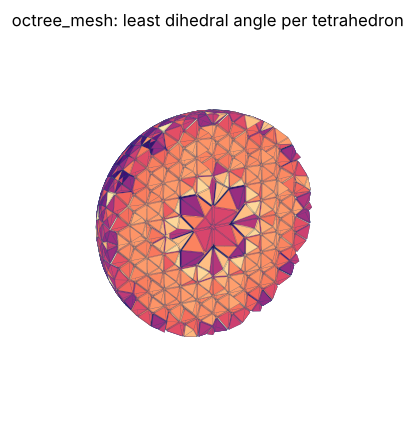

In [2]:
skin = mp.icosa_sphere(1.0, 4)
tets, rep = mp.octree_mesh(skin, min_size=0.04, return_report=True)
d0 = dihedrals(tets)
print('tetrahedra      :', len(d0))
print('least angle     : %.2f degrees' % d0.min())
print('under 20 degrees:', int((d0 < 20).sum()))
shown = tets.copy()
shown.cell_data = {'least angle': [d0]}
render_cutaway(shown, 'octree_mesh: least dihedral angle per tetrahedron', scalars='least angle', cmap='magma')

## `adapt_volume`

By default the size field keeps the boundary's own resolution and grows inside at most by `hgrad - 1` per unit length. At MMG's default gradation, 1.3, the octree's 2:1 grading is coarser inside than that, so the interior gains tetrahedra; at a looser gradation it loses them. `boundary_sizing="geometry"` sizes the boundary by curvature instead, `sqrt(8 hausd R)`, as MMG does, so the boundary coarsens too. Every run keeps the boundary within `hausd` and the least angle above the floor.

In [3]:
results = {}
for sizing in ('input', 'geometry'):
    for hgrad in (1.3, 2.0):
        out, r = mp.adapt_volume(tets, hgrad=hgrad, boundary_sizing=sizing, return_report=True)
        results[sizing, hgrad] = (out, r)
        print('%-8s hgrad %.1f: %d -> %d tetrahedra, least angle %.2f -> %.2f, boundary within %.4f (hausd %.4f)'
              % (sizing, hgrad, r['num_tets_before'], r['num_tets_after'], r['min_dihedral_before'],
                 r['min_dihedral_after'], r['max_boundary_deviation'], r['hausd']))
r = results['geometry', 1.3][1]
print('refused by guard (geometry, 1.3):', {k[len('num_rejected_by_'):]: r[k] for k in r if k.startswith('num_rejected_by_')})

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 75, 51)
ax.hist(d0, bins=bins, alpha=0.5, label='octree_mesh', color='#9ca3af')
for key, color in ((("input", 1.3), '#3b82f6'), (("geometry", 1.3), '#e63946')):
    ax.hist(dihedrals(results[key][0]), bins=bins, alpha=0.6, label=f'adapt_volume, {key[0]} sizes', color=color)
ax.set(xlabel='least dihedral angle of a tetrahedron (degrees)', ylabel='tetrahedra', yscale='log')
ax.legend()
plt.tight_layout()
plt.show()

adapted = results['geometry', 1.3][0].copy()
adapted.cell_data = {'least angle': [dihedrals(adapted)]}
render_cutaway(adapted, 'adapt_volume (geometry sizes): least dihedral angle per tetrahedron', scalars='least angle',
               cmap='magma', save='adapt_volume_sphere')

## Features and materials

A box keeps its corners and edges; two nested shells meshed by `conformity="cleaving"` keep their two materials, each on its side of the interface.

box: 3072 -> 470 tetrahedra, 8 corners, 12 chains, volume 1.000000000000


nested shells: 30648 -> 23547 tetrahedra, materials kept: ['material_1', 'material_2']
volume change per material class: {'block 0 inside material_1 octree_mesh:material=1': -0.005583, 'block 0 inside material_2 octree_mesh:material=2': -0.001603}


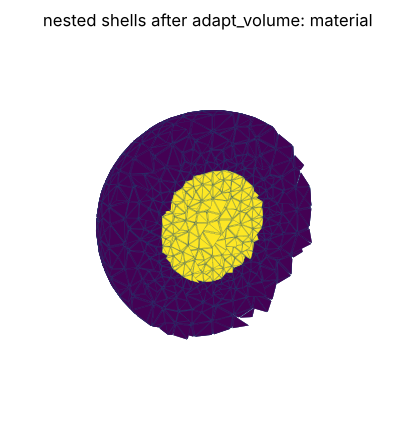

In [5]:
box = mp.box(dims=(8, 8, 8), cell_type='tetra')
out, r = mp.adapt_volume(box, hmin=0.3, hmax=0.4, return_report=True)
print('box: %d -> %d tetrahedra, %d corners, %d chains, volume %.12f' %
      (r['num_tets_before'], r['num_tets_after'], r['num_corners'], r['num_chains'], r['volume_after']))

shells = mp.merge([mp.icosa_sphere(1.0, 4), mp.icosa_sphere(0.5, 3)])
nested = mp.octree_mesh(shells, max_size=0.4, min_size=0.05, conformity='cleaving')
out, r = mp.adapt_volume(nested, return_report=True)
print('nested shells: %d -> %d tetrahedra, materials kept:' % (r['num_tets_before'], r['num_tets_after']),
      sorted(k for k in out.cell_sets if k.startswith('material_')))
print('volume change per material class:', {k: round(v, 6) for k, v in r['region_volume_change'].items()})
shown = out.copy()
shown.cell_data = {'material': [np.asarray(out.cell_data['octree_mesh:material'][0], dtype=float)]}
render_cutaway(shown, 'nested shells after adapt_volume: material', scalars='material', cmap='viridis')

## As an `octree_mesh` post-stage, and against MMG

`post_adapt=True` runs the same operation inside `octree_mesh`, before its quality report. With the optional MMG add-on (`meshioplusplus-mmg`, LGPL), or MMG's `mmg3d` program on `PATH`, the same parameters go to `mmg3d` for comparison; without either that row is skipped.

In [6]:
import shutil

post, rep2 = mp.octree_mesh(skin, min_size=0.04, post_adapt=True, adapt_boundary_sizing='geometry', return_report=True)
print('octree_mesh + post_adapt: %d tetrahedra, least angle %.2f, hausdorff to the skin %.4f (stages: %s)'
      % (rep2['num_tetrahedra'], rep2['min_dihedral'], rep2['hausdorff_to_skin'], ', '.join(rep2['timings'])))
r = results['geometry', 1.3][1]
mmg3d = shutil.which('mmg3d_O3') or shutil.which('mmg3d')
mm = None
if mp.has_mmg():
    mm = mp.adapt(tets, hmin=r['hmin'], hmax=r['hmax'], hgrad=1.3, hausd=r['hausd'])
elif mmg3d:
    # MMG's own program on a Medit file: nothing is linked
    with tempfile.TemporaryDirectory() as d:
        mp.write(os.path.join(d, 'in.mesh'), mp.Mesh(tets.points, [b for b in tets.cells if b.type == 'tetra']))
        subprocess.run([mmg3d, '-in', os.path.join(d, 'in.mesh'), '-out', os.path.join(d, 'out.mesh'),
                        '-hmin', str(r['hmin']), '-hmax', str(r['hmax']), '-hgrad', '1.3',
                        '-hausd', str(r['hausd']), '-v', '-1'], check=True, capture_output=True)
        out = mp.read(os.path.join(d, 'out.mesh'))
        mm = mp.Mesh(out.points, [b for b in out.cells if b.type == 'tetra'])
if mm is not None:
    d = dihedrals(mm)
    print('mmg3d                   : %d tetrahedra, least angle %.2f' % (len(d), d.min()))
else:
    print('MMG is not installed here: its comparison is skipped (the meshioplusplus-mmg add-on, or mmg3d on PATH).')

## Elsewhere

Both CLIs take `adapt-volume IN OUT --hmin --hmax --hgrad --hausd --preserve-boundary --max-iterations --json` and `octree-mesh ... --post-adapt --adapt-*`; the pipeline step is `AdaptVolume`; the C (`mio_adapt_volume`), Fortran, Julia, R, Octave, WebAssembly (`adaptVolume`) bindings and the MCP tool report the same counters. `tools/adapt_volume_bench.py` measures the table in `doc/adapt_volume.md`.